# Assignment: Huffman Encoding (Greedy)

In [ ]:
import heapq

class Node:
    def __init__(self, char=None, freq=0, left=None, right=None):
        self.char = char
        self.freq = freq
        self.left = left
        self.right = right

    def __lt__(self, other):
        return self.freq < other.freq


def count_frequencies(text):
    frequencies = {}
    for char in text:
        if char in frequencies:
            frequencies[char] += 1
        else:
            frequencies[char] = 1
    return frequencies


def huffman(text):
    frequencies = count_frequencies(text)
    if not frequencies:
        return {}

    heap = [Node(char, freq) for char, freq in frequencies.items()]
    heapq.heapify(heap)

    if len(heap) == 1:
        return {heap[0].char: "0"}

    while len(heap) > 1:
        left = heapq.heappop(heap)
        right = heapq.heappop(heap)
        parent = Node(freq=left.freq + right.freq, left=left, right=right)
        heapq.heappush(heap, parent)

    codes = {}

    
    def generate(node, code=""):
        if node.char is not None:
            codes[node.char] = code
        else:
            generate(node.left, code + "0")
            generate(node.right, code + "1")

    generate(heap[0])
    print("Codes: ", codes)

    return codes


text = "this is an example for huffman encoding"
frequencies = count_frequencies(text)
codes = huffman(text)

print("Character : Frequency : Huffman Code")
for char, freq in frequencies.items():
    print(f"{repr(char):^12} : {freq:^9} : {codes[char]}")

print("\nTime and Space Complexity")
print("Time : O(k log k)  [k = unique characters]")
print("Space : O(k)")

Codes:  {'n': '000', 's': '0010', 'm': '0011', 'h': '0100', 't': '01010', 'd': '01011', 'r': '01100', 'l': '01101', 'x': '01110', 'c': '01111', 'p': '10000', 'g': '10001', 'i': '1001', ' ': '101', 'u': '11000', 'o': '11001', 'f': '1101', 'e': '1110', 'a': '1111'}
Character : Frequency : Huffman Code
    't'      :     1     : 01010
    'h'      :     2     : 0100
    'i'      :     3     : 1001
    's'      :     2     : 0010
    ' '      :     6     : 101
    'a'      :     3     : 1111
    'n'      :     4     : 000
    'e'      :     3     : 1110
    'x'      :     1     : 01110
    'm'      :     2     : 0011
    'p'      :     1     : 10000
    'l'      :     1     : 01101
    'f'      :     3     : 1101
    'o'      :     2     : 11001
    'r'      :     1     : 01100
    'u'      :     1     : 11000
    'c'      :     1     : 01111
    'd'      :     1     : 01011
    'g'      :     1     : 10001

Time and Space Complexity
Time : O(k log k)  [k = unique characters]
Space : O(k)


# Analysis: Time and Memory Comparison

Unique Characters	Time (s)	Peak Memory (KB)
2			0.00002270	0.9219
3			0.00002220	1.2715
4			0.00002310	1.4961
5			0.00002420	1.8164
6			0.00002600	2.3213
7			0.00002660	2.5996
8			0.00002630	2.7529
9			0.00002730	3.1377
10			0.00002840	3.3857
11			0.00002930	4.2432
12			0.00003160	4.4473
13			0.00003230	4.6514
14			0.00003460	4.8867
15			0.00003560	5.0908
16			0.00003590	5.2178
17			0.00003610	5.5420
18			0.00003910	5.7910
19			0.00003990	6.0400
20			0.00004215	6.2891
21			0.00004450	6.5381
22			0.00004340	7.9277
23			0.00004530	8.1318
24			0.00004430	8.3359
25			0.00004760	8.5400
26			0.00004570	8.7441
27			0.00004780	8.9795
28			0.00004820	9.1836
29			0.00005140	9.3877
30			0.00005100	9.5918
31			0.00005280	9.7471
32			0.00005360	9.9648
33			0.00005460	10.2910
34			0.00005720	10.5410
35			0.00005830	10.7910
36			0.00005990	11.0410
37			0.00006030	11.2910
38			0.00006080	11.5410
39			0.00006260	11.7910
40			0.00006370	12.0410
41			0.00006680	12.2910
42			0.00006700	12.5410
43			0.0000

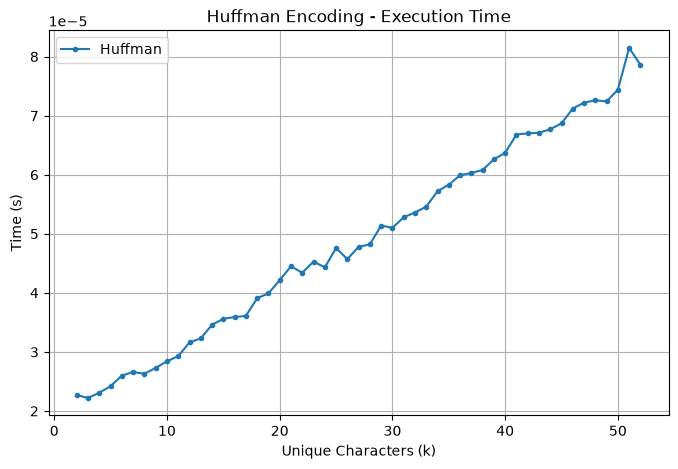

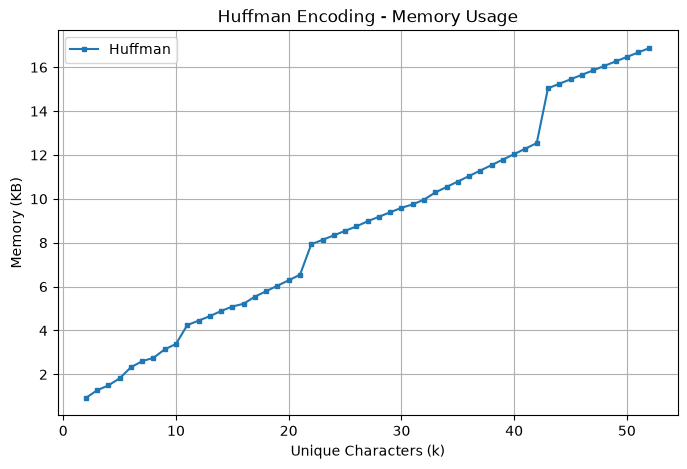

In [16]:
import matplotlib.pyplot as plt
from time import perf_counter
import tracemalloc
import statistics
import string


def measure_time(function, text, repeats=1000):
    times = []
    for _ in range(repeats):
        start = perf_counter()
        function(text)
        times.append(perf_counter() - start)
    return statistics.median(times)


def measure_memory(function, text, repeats=3):
    memory_values = []
    for _ in range(repeats):
        tracemalloc.start()
        function(text)
        _, peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        memory_values.append(peak / 1024)
    return statistics.median(memory_values)


alphabet = string.ascii_letters
x = list(range(2, len(alphabet) + 1))
execution_times = []
memory_usage = []

for k in x:
    test_text = "".join(alphabet[i % k] for i in range(1000))
    execution_times.append(measure_time(huffman, test_text))
    memory_usage.append(measure_memory(huffman, test_text))


print("Unique Characters\tTime (s)\tPeak Memory (KB)")
for k, t, m in zip(x, execution_times, memory_usage):
    print(f"{k}\t\t\t{t:.8f}\t{m:.4f}")


plt.figure(figsize=(8, 5))
plt.plot(x, execution_times, marker='o', markersize=3, label="Huffman")
plt.xlabel("Unique Characters (k)")
plt.ylabel("Time (s)")
plt.title("Huffman Encoding - Execution Time")
plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(8, 5))
plt.plot(x, memory_usage, marker='s', markersize=3, label="Huffman")
plt.xlabel("Unique Characters (k)")
plt.ylabel("Memory (KB)")
plt.title("Huffman Encoding - Memory Usage")
plt.legend()
plt.grid(True)
plt.show()